# 09 — Day 9 Evaluation: Pitch-Shift Augmentation on WavLM Layer 6

**Standalone**, same pattern as `08a_evaluate_wavlm_augmented.ipynb`. Tests pitch-shift augmentation
(a different acoustic axis than Day 8a's speed/tempo perturbation) on WavLM layer 6.

**Two configurations, deliberately fewer than Day 6/8a's four — PCA is skipped here on purpose:**
Day 6 (HuBERT) and Day 8a (WavLM, speed) both already found PCA hurts once augmentation is
involved, tested twice now on two different embeddings. Re-testing it a third time here would be
low-value repetition, not genuine one-variable-at-a-time exploration — so this notebook stays
focused on the one new variable (pitch vs. speed as the augmentation axis):

1. Pitch-shifted WavLM L6 alone (no fusion).
2. Pitch-shifted WavLM L6 + session-level fusion.

**No permutation test here** — reserved for Day 10's single finalized candidate.

**Inputs needed (Kaggle "Add Input") — 3 total:**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **Day 7's `07_features_wavlm.ipynb`** output — for `wavlm_base_plus_all_layers.parquet`.
3. **`09_features_wavlm_pitchshift.ipynb`**'s output — for `wavlm_layer6_pitchshift_augmented.parquet`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
LAYER = 6

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
WAVLM_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("wavlm_base_plus_all_layers.parquet"))
AUGMENTED_PARQUET = next(Path("/kaggle/input").rglob("wavlm_layer6_pitchshift_augmented.parquet"))

print(f"LABELS_CSV                = {LABELS_CSV}")
print(f"WAVLM_ALL_LAYERS_PARQUET  = {WAVLM_ALL_LAYERS_PARQUET}")
print(f"AUGMENTED_PARQUET         = {AUGMENTED_PARQUET}")

LABELS_CSV                = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
WAVLM_ALL_LAYERS_PARQUET  = /kaggle/input/notebooks/tapudatta/notebook1-day7/features/wavlm_base_plus_all_layers.parquet
AUGMENTED_PARQUET         = /kaggle/input/notebooks/tapudatta/notebook1-day9-features/features/wavlm_layer6_pitchshift_augmented.parquet


## 1. Combine Original + Pitch-Shifted Embeddings

Same shape as Day 8a section 1, with `speed_factor` renamed `pitch_shift` and `1.0` (original speed)
replaced by `0` (no pitch shift).

In [2]:
labels = pd.read_csv(LABELS_CSV)
wavlm_all_layers = pd.read_parquet(WAVLM_ALL_LAYERS_PARQUET)
augmented = pd.read_parquet(AUGMENTED_PARQUET)

layer_cols = [c for c in wavlm_all_layers.columns if c.startswith(f"layer{LAYER}_emb_")]
assert len(layer_cols) == 1536, f"expected 1536 layer-{LAYER} columns, got {len(layer_cols)}"
original_layer6 = wavlm_all_layers[["filename"] + layer_cols].copy()
original_layer6.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]
original_layer6["pitch_shift"] = 0

augmented = augmented.rename(columns={"source_filename": "filename"})

combined_emb = pd.concat([original_layer6, augmented], ignore_index=True, sort=False)
assert len(combined_emb) == 280 * 3, f"expected 840 combined rows, got {len(combined_emb)}"

df_aug = labels.merge(combined_emb, on="filename", how="inner").reset_index(drop=True)
assert len(df_aug) == 280 * 3, f"expected 840 rows after merge, got {len(df_aug)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df_aug["y"] = df_aug["label"].map(LABEL_MAP)
assert df_aug["y"].isna().sum() == 0
df_aug["is_original"] = df_aug["pitch_shift"] == 0

per_filename_participants = df_aug.groupby("filename")["participant_id"].nunique()
assert (per_filename_participants == 1).all(), \
    "a filename maps to more than one participant_id across its pitch variants -- bug"

emb_cols = [c for c in df_aug.columns if c.startswith("emb_")]
X = df_aug[emb_cols].to_numpy()
y = df_aug["y"].to_numpy()
groups = df_aug["participant_id"].to_numpy()
is_original = df_aug["is_original"].to_numpy()

print(f"Total rows: {len(df_aug)} (280 original + 560 pitch-shifted)")
print(f"X: {X.shape}, original rows: {is_original.sum()}, augmented rows: {(~is_original).sum()}")
print("Checked: every recording's original + pitch-shifted copies share exactly one participant_id.")

Total rows: 840 (280 original + 560 pitch-shifted)
X: (840, 1536), original rows: 280, augmented rows: 560
Checked: every recording's original + pitch-shifted copies share exactly one participant_id.


## 2. Shared Candidates & Augmentation-Aware Nested CV (duplicated from `06_evaluate_combined.ipynb`)

Plain 10-candidate set only (no PCA — see rationale above). `nested_loso_cv_augmented_variant` is
unchanged from every prior day: training pools get original + pitch-shifted rows, every scored fold
(outer test, inner validation) uses original rows only.

In [3]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (f"{name}_C={c}", build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [4]:
def nested_loso_cv_augmented_variant(X, y, groups, is_original, make_candidates_fn,
                                      n_inner_splits=6, expected_n_scored=None):
    participants = np.unique(groups)
    oof_scores = np.full(len(y), np.nan)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = (groups == test_participant) & is_original
        outer_train_mask = groups != test_participant
        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        is_orig_tr = is_original[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            inner_val_idx = inner_val_idx[is_orig_tr[inner_val_idx]]
            if len(inner_val_idx) == 0:
                continue
            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[np.where(outer_test_mask)[0]] = test_scores

        fold_records.append({"test_participant": test_participant, "chosen_label": best_label,
                              "inner_cv_auc": mean_aucs[best_i]})

    print(f"  Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    n_scored = int(np.sum(~np.isnan(oof_scores)))
    print(f"  Scored {n_scored} original rows.")
    if expected_n_scored is not None:
        assert n_scored == expected_n_scored, f"expected {expected_n_scored} scored rows, got {n_scored}"
    return oof_scores, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


def summarize(y, oof_scores, groups):
    valid = ~np.isnan(oof_scores)
    y_v, s_v, g_v = y[valid], oof_scores[valid], groups[valid]
    auc = roc_auc_score(y_v, s_v)
    lo, hi, _ = bootstrap_auc_ci(g_v, y_v, s_v)
    return auc, lo, hi, int(valid.sum())


results_log = []


def run_variant(name, X_in, y_in, groups_in, is_original_in, make_candidates_fn, expected_n_scored=None):
    print(f"=== {name} ===")
    oof_scores, fold_info = nested_loso_cv_augmented_variant(
        X_in, y_in, groups_in, is_original_in, make_candidates_fn, expected_n_scored=expected_n_scored
    )
    auc, ci_lo, ci_hi, n_scored = summarize(y_in, oof_scores, groups_in)
    print(f"  Pooled AUC = {auc:.3f}  (95% CI [{ci_lo:.3f}, {ci_hi:.3f}], N={n_scored})\n")
    results_log.append({"variant": name, "N": n_scored, "auc": auc, "ci_lo": ci_lo, "ci_hi": ci_hi})
    return auc

## 3. Configuration #1 — Pitch-Shifted WavLM L6 (no fusion)

Does the added training volume from pitch-shifted copies help, given they don't touch the
tempo/speaking-rate dimension that Day 8a's speed-shift found WavLM leans on?

In [5]:
auc_baseline = run_variant(
    "Pitch-shifted WavLM L6 (no fusion)", X, y, groups, is_original, make_candidates, expected_n_scored=280,
)
print("Reference -- Day 7 plain WavLM L6: AUC 0.663, CI [0.600, 0.710]")
print("Reference -- Day 8a speed-augmented WavLM L6 (no fusion): AUC 0.643, CI [0.590, 0.701]")

=== Pitch-shifted WavLM L6 (no fusion) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
  Pooled AUC = 0.628  (95% CI [0.568, 0.698], N=280)

Reference -- Day 7 plain WavLM L6: AUC 0.663, CI [0.600, 0.710]
Reference -- Day 8a speed-augmented WavLM L6 (no fusion): AUC 0.643, CI [0.590, 0.701]


## 4. Configuration #2 — Pitch-Shifted WavLM L6 + Session-Level Fusion

Same construction as Day 6/8a: a session's fused vector concatenates its three activities' embeddings
at the same pitch-shift value (never mixed across shifts, same reasoning as the speed-factor version).

In [6]:
ACTIVITY_ORDER = ["read_aloud", "read_aloud_nonsense", "describe_picture"]


def build_session_features_augmented(df_aug, emb_cols):
    rows = []
    for (participant, session, shift), group in df_aug.groupby(
        ["participant_id", "session_number", "pitch_shift"]
    ):
        by_activity = group.set_index("activity_type")
        if not all(a in by_activity.index for a in ACTIVITY_ORDER):
            continue
        feats = np.concatenate([by_activity.loc[a, emb_cols].to_numpy(dtype=float) for a in ACTIVITY_ORDER])
        rows.append({
            "participant_id": participant, "session_number": session, "pitch_shift": shift,
            "y": int(by_activity["y"].iloc[0]), "is_original": bool(shift == 0), "features": feats,
        })
    return pd.DataFrame(rows)


session_feat_df = build_session_features_augmented(df_aug, emb_cols)
X_session = np.vstack(session_feat_df["features"].to_numpy())
y_session = session_feat_df["y"].to_numpy()
groups_session = session_feat_df["participant_id"].to_numpy()
is_original_session = session_feat_df["is_original"].to_numpy()
n_original_sessions = int(is_original_session.sum())

print(f"Session x pitch-shift dataset: {X_session.shape}, {n_original_sessions} original sessions to score")

auc_fusion = run_variant(
    "Pitch-shifted WavLM L6 + session-level fusion",
    X_session, y_session, groups_session, is_original_session, make_candidates, expected_n_scored=n_original_sessions,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")
print("Reference -- Day 8a speed-augmented + fusion: AUC 0.638, CI [0.596, 0.713]")

Session x pitch-shift dataset: (276, 4608), 92 original sessions to score
=== Pitch-shifted WavLM L6 + session-level fusion ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 92 original rows.
  Pooled AUC = 0.643  (95% CI [0.586, 0.732], N=92)

vs. baseline (config #1): 0.628
Reference -- Day 8a speed-augmented + fusion: AUC 0.638, CI [0.596, 0.713]


## 5. Day 9 Pitch-Shift Results

                                      variant   N      auc    ci_lo    ci_hi
           Pitch-shifted WavLM L6 (no fusion) 280 0.627947 0.567908 0.698191
Pitch-shifted WavLM L6 + session-level fusion  92 0.643094 0.585588 0.732282


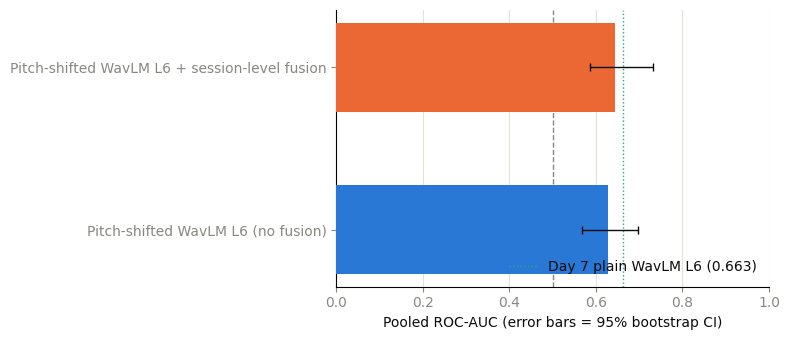


Best pitch-shift configuration: Pitch-shifted WavLM L6 + session-level fusion  AUC=0.643  CI=[0.586, 0.732]
No permutation test run here -- reserved for Day 10's final buffer.


In [7]:
results_df = pd.DataFrame(results_log)
print(results_df.to_string(index=False))

DAY9_COLORS = ["#2a78d6", "#eb6834"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 3.5))
y_pos = np.arange(len(results_df))
ax.barh(y_pos, results_df["auc"], color=DAY9_COLORS[: len(results_df)], height=0.55, zorder=3)
ax.errorbar(
    results_df["auc"], y_pos,
    xerr=[results_df["auc"] - results_df["ci_lo"], results_df["ci_hi"] - results_df["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.axvline(0.663, color="#1baf7a", linewidth=1, linestyle=":", zorder=2, label="Day 7 plain WavLM L6 (0.663)")
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK, loc="lower right")
plt.tight_layout()
plt.show()

best_idx = results_df["auc"].idxmax()
print(f"\nBest pitch-shift configuration: {results_df.loc[best_idx, 'variant']}  "
      f"AUC={results_df.loc[best_idx, 'auc']:.3f}  "
      f"CI=[{results_df.loc[best_idx, 'ci_lo']:.3f}, {results_df.loc[best_idx, 'ci_hi']:.3f}]")
print("No permutation test run here -- reserved for Day 10's final buffer.")

## How to read Day 9's pitch-shift results

- **Beats Day 7's plain WavLM L6 (0.663) clearly**, CI lower bound moving up too: pitch is a
  productive augmentation axis for WavLM even though tempo wasn't (Day 8a) -- worth re-ensembling
  with plain HuBERT (Day 8b's recipe) to see if it pushes the ensemble past 0.676/0.678.
- **Close to 0.663 with heavily overlapping CIs, or below it**: pitch-shift doesn't help WavLM
  either -- consistent with the added training volume simply not outweighing whatever cost any
  perturbation-based augmentation imposes on this embedding at this sample size, regardless of which
  acoustic axis is perturbed. Carry Day 7's plain WavLM L6 forward, same as Day 8a's verdict.
- **Fusion (#2) vs. baseline (#1) split**: informative on its own, same as every prior fusion test.

**No permutation test yet.** Update `PROJECT_PLAN.md`'s Day 7+ roadmap section with today's numbers,
then check `09_evaluate_wavlm_mixup.ipynb`'s results before deciding what (if anything) advances to
a re-ensembling step.